# Project 3 · EDA and Feature Engineering
**Mapping Recycling Inequities: Predicting Waste Diversion Across NYC Communities**

| | |
|---|---|
| **Title** | DSC450_Project3_EDA_Feature_Engineering |
| **Author** | Hali Sarah Parsons (Data Scientist, Sprint 3) |
| **Date** | 2026-11-10 |
| **Modified By** | Claude (v2: Matt's final REBUILT data, ACS income, date-aware lags) |
| **Description** | Explores Matt's final wrangled DSNY, LEP, housing and ACS income data, engineers model features, and sets the baselines the models must beat. |

### How this notebook follows the course readings
The plan follows the data mining process in *Data Science for Business* (Provost & Fawcett, 2013, Ch. 2): business understanding first, then data understanding and preparation, with modeling saved for the next notebook. Five rules from the readings shape every step.

1. **Know the decision.** DSNY wants to know where to send outreach. Every feature has to describe something about a district that the city could know before it plans that outreach.
2. **Watch for leakage.** A feature cannot carry information that only exists after the outcome (Provost & Fawcett, 2013, Ch. 2). Refuse, paper and MGP tons make up the target, so none of them becomes a feature. Forecast features only use months before the month being predicted.
3. **Beat a baseline.** A model only adds value if it beats a simple one, such as always guessing the average or repeating last year (Provost & Fawcett, 2013, Ch. 5 and Ch. 7). Section 8 measures those baselines now so the models have a fixed bar to clear.
4. **Respect the sample size.** The cross-sectional data has only 59 districts. Many features chasing few rows is how lucky, meaningless patterns appear (Stephens-Davidowitz, 2017, Ch. 7). We keep the feature list short and attach uncertainty to every correlation.
5. **Associations are not causes.** District-level patterns describe neighborhoods, not households, and the collection share measures only what can be measured (Stephens-Davidowitz, 2017, Ch. 7).

## 1. Setup
In Colab, upload `P3_Final_Data_Wrangling.zip` (Matt's final handoff) to the Files panel, then run all cells. The next cell unzips it if the folder isn't there yet.

In [1]:
# WHY these libraries: pandas/numpy for the tables, matplotlib for static figures Andrea can drop into the report.
import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "P3_Final_Data_Wrangling/outputs"
# WHY: Colab starts empty each session, so unpack the uploaded handoff zip only when the folder is missing.
if not os.path.isdir(DATA_DIR) and os.path.exists("P3_Final_Data_Wrangling.zip"):
    with zipfile.ZipFile("P3_Final_Data_Wrangling.zip") as z:
        z.extractall(".")
os.makedirs("figures", exist_ok=True)
os.makedirs("features", exist_ok=True)

# WHY a fixed seed: bootstrap intervals below should give the same numbers every run.
RNG = np.random.default_rng(450)

# Borough colors, fixed per borough on every chart (validated for color-vision deficiency).
BORO_COLORS = {"Manhattan": "#2a78d6", "Bronx": "#eb6834", "Brooklyn": "#1baf7a",
               "Queens": "#eda100", "Staten Island": "#e87ba4"}
BORO_ORDER = list(BORO_COLORS)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9})

## 2. Load and check the data
Before exploring, confirm the tables are what the handoff says: one row per district, 59 districts, matching keys, no impossible tonnages.

In [2]:
# WHY the ACS file: it is Matt's REBUILT master plus the ACS income columns, so one file holds every district feature.
district = pd.read_csv(f"{DATA_DIR}/district_master_2025_acs_income_CANDIDATE_REVIEW_ONLY.csv")
monthly = pd.read_csv(f"{DATA_DIR}/dsny_monthly_complete_2005_2026_10_REBUILT.csv", parse_dates=["month"])
income_cmp = pd.read_csv(f"{DATA_DIR}/income_comparison_Sarah_Matt_59districts.csv")

# WHY asserts: if a later handoff changes shape, the notebook stops here instead of producing quietly wrong results.
assert district["boro_cd"].is_unique and len(district) == 59, "district master should have 59 unique districts"
assert set(monthly["boro_cd"]) == set(district["boro_cd"]), "monthly and master district keys differ"
tons = ["refusetonscollected", "papertonscollected", "mgptonscollected"]
assert (monthly[tons] >= 0).all().all(), "negative tonnage found"
assert monthly["core_complete"].all(), "the REBUILT monthly file should only hold complete months"
assert (district["complete_months"] == 12).all(), "a district is missing 2025 months"

print("Districts:", len(district), "| Monthly rows:", len(monthly),
      "| Months:", monthly["month"].min().date(), "to", monthly["month"].max().date())

Districts: 59 | Monthly rows: 15458 | Months: 2005-01-01 to 2026-10-01


### Is the monthly history unbroken?
Matt's REBUILT file keeps only months with complete refuse, paper and MGP tonnage, from January 2005 on. A lag only means "last month" or "last year" if no months are missing, so check that every district has every month.

In [3]:
n_months = monthly["month"].nunique()
per_cd = monthly.groupby("boro_cd")["month"].agg(["count", "min", "max"])
# WHY: an unbroken series has exactly one row per calendar month between its first and last month.
expected = pd.date_range(monthly["month"].min(), monthly["month"].max(), freq="MS")
assert (per_cd["count"] == len(expected)).all(), "a district is missing months"
first_full = int(monthly["year"].min())
print(f"{per_cd['count'].iloc[0]} months x 59 districts = {len(monthly):,} rows, {expected[0].date()} to {expected[-1].date()}, no gaps")

262 months x 59 districts = 15,458 rows, 2005-01-01 to 2026-10-01, no gaps


## 3. The target: 2025 recycling collection share
`recycling_share_2025_pct` = (paper + MGP tons) ÷ (refuse + paper + MGP tons) × 100.

This is narrower than DSNY's published diversion rate because it leaves out organics, and it measures what was **collected**, not what was actually recycled after sorting. That is the "overemphasis on what is measurable" risk from *Everybody Lies*: the share is a proxy for recycling behavior, not the behavior itself.

In [4]:
y = "recycling_share_2025_pct"
print(district[y].describe().round(2).to_string())
city_share = district["dry_recycling_tons"].sum() / (district["refuse_tons"] + district["dry_recycling_tons"]).sum() * 100
print(f"\nCitywide 2025 share (tonnage-weighted): {city_share:.1f}%")

low = district.nsmallest(5, y)[["boro_cd", "borough", y]]
high = district.nlargest(5, y)[["boro_cd", "borough", y]]
print("\nLowest 5:\n", low.round(1).to_string(index=False))
print("\nHighest 5:\n", high.round(1).to_string(index=False))

# WHY IQR outlier rule: flags districts so extreme they could drive the models by themselves.
q1, q3 = district[y].quantile([.25, .75])
fence = (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
print("\nOutside 1.5×IQR fences:", district.loc[~district[y].between(*fence), "boro_cd"].tolist() or "none")

count    59.00
mean     17.36
std       5.18
min       5.14
25%      13.73
50%      17.18
75%      20.41
max      28.45

Citywide 2025 share (tonnage-weighted): 16.9%

Lowest 5:
  boro_cd   borough  recycling_share_2025_pct
     202     Bronx                       5.1
     110 Manhattan                       8.1
     316  Brooklyn                       8.6
     308  Brooklyn                       9.0
     201     Bronx                      10.3

Highest 5:
  boro_cd   borough  recycling_share_2025_pct
     306  Brooklyn                      28.4
     101 Manhattan                      27.3
     107 Manhattan                      26.8
     106 Manhattan                      25.3
     302  Brooklyn                      25.1

Outside 1.5×IQR fences: none


### Figure: every district ranked within its borough

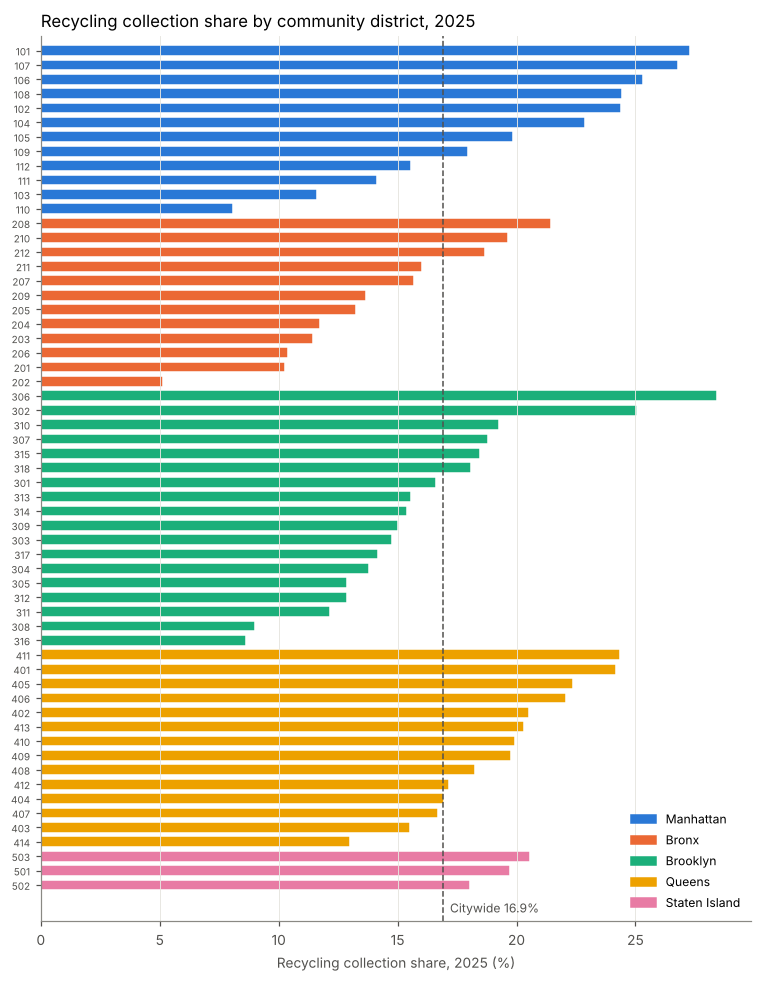

In [5]:
d = district.copy()
d["boro_rank"] = d["borough"].map({b: i for i, b in enumerate(BORO_ORDER)})
d = d.sort_values(["boro_rank", y], ascending=[False, True]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(d.index, d[y], color=d["borough"].map(BORO_COLORS), height=0.75, edgecolor="white", linewidth=1)
ax.set_yticks(d.index, d["boro_cd"].astype(str), fontsize=6.5)
ax.axvline(city_share, color="#52514e", lw=1, ls="--")
ax.text(city_share + 0.3, -1.6, f"Citywide {city_share:.1f}%", fontsize=8, color="#52514e", va="center")
ax.set_ylim(-2.5, len(d))  # WHY extra room at the bottom: the citywide label sits clear of the bars
ax.set_xlabel("Recycling collection share, 2025 (%)")
ax.set_title("Recycling collection share by community district, 2025", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=BORO_COLORS[b]) for b in BORO_ORDER]
ax.legend(handles, BORO_ORDER, loc="lower right", frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig1_district_ranking_2025.png", dpi=200); plt.show()

### Borough shares
Borough shares come from **summed tonnages**, not the average of district percentages. Averaging percentages would give a small district the same weight as a large one.

               refuse_tons  dry_recycling_tons  share  district_spread_pp
borough                                                                  
Manhattan         511772.9            120905.8   19.1                19.2
Bronx             520904.3             78599.1   13.1                16.3
Brooklyn          946196.7            172931.3   15.5                19.8
Queens            727229.9            170883.3   19.0                11.3
Staten Island     180043.2             43699.1   19.5                 2.5


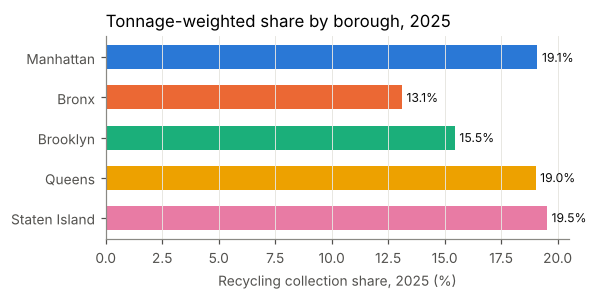

In [6]:
boro = (district.groupby("borough")[["refuse_tons", "dry_recycling_tons"]].sum()
        .assign(share=lambda t: t.dry_recycling_tons / (t.refuse_tons + t.dry_recycling_tons) * 100)
        .reindex(BORO_ORDER))
boro["district_spread_pp"] = district.groupby("borough")[y].agg(lambda s: s.max() - s.min()).reindex(BORO_ORDER)
print(boro.round(1).to_string())

fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.barh(boro.index[::-1], boro["share"][::-1], color=[BORO_COLORS[b] for b in boro.index[::-1]], height=0.6)
for i, (b, v) in enumerate(boro["share"][::-1].items()):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=8, color="#0b0b0b")
ax.set_xlabel("Recycling collection share, 2025 (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Tonnage-weighted share by borough, 2025", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fig2_borough_share_2025.png", dpi=200); plt.show()

## 4. Choosing the income source
Two income sources exist:

| | Furman 2024 (Sarah's first pass) | NYC Planning ACS 2020–2024 (Matt) |
|---|---|---|
| Geography | 55 sub-borough areas, mapped to 59 districts | 59 Community District Tabulation Areas |
| Shared values | 8 districts share 4 values | none |
| Missing | Bronx 7, filled with Bronx median | none |
| Margin of error | not provided | provided (except Manhattan 1) |

**Decision: ACS is the main income feature.** We chose it on data quality, before looking at any model scores. Picking whichever source scores better on 59 districts would reward luck, which is the overfitting trap Provost & Fawcett (2013, Ch. 5) warn about. Furman income stays as a **sensitivity check**: if the conclusions hold with both sources, the finding is stronger.

Two cautions carried forward:
- CDTAs approximate community districts. 46 of 59 are marked "approximation."
- Manhattan 1 reports exactly $200,000 with no margin of error, which looks like a top-coded value. Rank-based methods and the log scale limit its pull, and Section 6 reruns the key correlation without it.

In [7]:
acs = district["income_median_household_usd"]
moe_pct = district["income_moe_usd"] / acs * 100
print(f"ACS margin of error as % of estimate: median {moe_pct.median():.1f}%, max {moe_pct.max():.1f}%")
print("Boundary match:", district["income_boundary_label"].value_counts().to_dict())
print("Flagged:", district.loc[district["income_moe_missing"] == 1, ["boro_cd", "income_median_household_usd"]].to_dict("records"))
both = income_cmp.rename(columns={"sarah_furman_2024_sba_income_usd": "furman", "matt_nyc_planning_acs_2020_2024_cdta_income_usd": "acs"})
print(f"Furman vs ACS rank agreement (Spearman): {both[['furman', 'acs']].corr(method='spearman').iloc[0, 1]:.2f}")
print(f"Median absolute gap: {both['sarah_minus_matt_usd'].abs().median():,.0f} USD")

ACS margin of error as % of estimate: median 4.6%, max 8.8%
Boundary match: {'Approximation': 46, 'Equivalent': 13}
Flagged: [{'boro_cd': 101, 'income_median_household_usd': 200000.0}]
Furman vs ACS rank agreement (Spearman): 0.98
Median absolute gap: 3,939 USD


## 5. Feature engineering
Each feature must be known **before** outreach is planned, and it cannot be built from the tonnages that make up the target.

| Feature | Built from | Why it might matter |
|---|---|---|
| `lep_pct` | LEP count ÷ population (ACS 2015–2019) | Language barriers to recycling instructions |
| `rent_stab_share` | Furman 2025 | Older multifamily rentals, shared bins |
| `nycha_share` | Furman 2025 | Public housing has its own collection setup |
| `permits_per_1k` | Residential units permitted ÷ population × 1,000 | Fast-growing districts; a raw count would just track district size |
| `log_income` | log of ACS 2020–2024 median household income | Income links to recycling in prior research; log because incomes are skewed |

**Left out on purpose:**
- Refuse, paper and MGP tons. They are the target's ingredients, so they would leak.
- Population density. It only exists on the 55-area Furman geography, Matt marked it provisional, and its link to recycling was too uncertain in the first pass (its interval crossed zero).
- Furman income, except as the sensitivity check.

In [8]:
feat = district[["boro_cd", "borough", y]].copy()
feat["hh_income"] = district["income_median_household_usd"].values
feat["income_flagged"] = district["income_moe_missing"].astype(bool).values
feat["furman_income"] = feat["boro_cd"].map(income_cmp.set_index("boro_cd")["sarah_furman_2024_sba_income_usd"])
feat["lep_pct"] = district["lep_pct_calculated"].values
feat["rent_stab_share"] = district["housing_rs_unit_share"].values
feat["nycha_share"] = district["housing_rent_pct_nycha"].values
# WHY per 1,000: the raw permit count mostly measures how big a district is, not how fast it is growing.
feat["permits_per_1k"] = (district["housing_nb_permit_res_units"] / district["population_estimate"] * 1000).values
# WHY log: income is right-skewed, so a log keeps a few very rich districts from dominating a linear model.
feat["log_income"] = np.log(feat["hh_income"])
feat["log_income_furman"] = np.log(feat["furman_income"])

# WHY a prior-year share: last year's share is known before this year's outreach, so it is a fair input
# for the risk model; it is kept separate because it would swamp the community features in the association model.
hist = (monthly.groupby(["boro_cd", "year"])[["dry_recycling_tons", "core_total_tons"]].sum()
        .assign(share=lambda t: t.dry_recycling_tons / t.core_total_tons * 100)["share"].unstack())
feat["share_2024"] = feat["boro_cd"].map(hist[2024])
feat["share_2019"] = feat["boro_cd"].map(hist[2019])

# WHY bottom quarter: the proposal defines high risk this way, giving a short outreach list of about 15 districts.
cut = feat[y].quantile(0.25)
feat["high_risk"] = (feat[y] <= cut).astype(int)

FEATURES = ["lep_pct", "rent_stab_share", "nycha_share", "permits_per_1k", "log_income"]
print(f"High-risk cutoff: {cut:.1f}%  |  high-risk districts: {feat.high_risk.sum()} of {len(feat)}")
print(feat[FEATURES + [y]].describe().T.round(2)[["mean", "std", "min", "max"]].to_string())

High-risk cutoff: 13.7%  |  high-risk districts: 15 of 59
                           mean    std    min    max
lep_pct                   21.28  12.73   4.21  49.62
rent_stab_share           39.91  17.76   5.43  83.47
nycha_share                6.02   7.26   0.00  28.60
permits_per_1k             2.57   3.34   0.00  18.26
log_income                11.26   0.44  10.29  12.21
recycling_share_2025_pct  17.36   5.18   5.14  28.45


### Leakage check
A quick guard that no target ingredient slipped into the feature list.

In [9]:
banned = {"refuse", "paper", "mgp", "dry_recycling", "core_total", "recycling_share"}
assert not [f for f in FEATURES if any(b in f for b in banned)], "a target ingredient is in FEATURES"
print("No target ingredients in FEATURES:", FEATURES)

No target ingredients in FEATURES: ['lep_pct', 'rent_stab_share', 'nycha_share', 'permits_per_1k', 'log_income']


## 6. How do the features relate to the target?
**Spearman correlations** handle skewed features and outliers better than Pearson. With only 59 districts, each correlation gets a **bootstrap 95% interval**: resample the districts 2,000 times and see how much the correlation moves. If the interval crosses zero, we don't treat the link as real.

In [10]:
def spearman_ci(a, b, reps=2000):
    '''Spearman rho with a percentile bootstrap 95% interval.

    WHY bootstrap: with n = 59 a single correlation can look strong by luck; resampling shows how stable it is.'''
    a, b = pd.Series(a).rank().values, pd.Series(b).rank().values
    rho = np.corrcoef(a, b)[0, 1]
    idx = RNG.integers(0, len(a), size=(reps, len(a)))
    boots = [np.corrcoef(pd.Series(a[i]).rank(), pd.Series(b[i]).rank())[0, 1] for i in idx]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return rho, lo, hi

rows = []
for f in FEATURES + ["log_income_furman", "share_2024", "share_2019"]:
    rho, lo, hi = spearman_ci(feat[f], feat[y])
    rows.append({"feature": f, "rho": rho, "ci_low": lo, "ci_high": hi, "crosses_zero": lo < 0 < hi})
corr_tbl = pd.DataFrame(rows).sort_values("rho")
print(corr_tbl.round(2).to_string(index=False))

# WHY drop Manhattan 1 once: its $200,000 looks top-coded, so check that the income link doesn't depend on it.
keep = feat["boro_cd"] != 101
print(f"\nIncome rho without Manhattan 1: {spearman_ci(feat.loc[keep, 'log_income'], feat.loc[keep, y])[0]:.2f}")

          feature   rho  ci_low  ci_high  crosses_zero
  rent_stab_share -0.35   -0.55    -0.13         False
          lep_pct -0.35   -0.58    -0.07         False
   permits_per_1k -0.35   -0.60    -0.07         False
      nycha_share -0.24   -0.48     0.02          True
log_income_furman  0.79    0.63     0.89         False
       log_income  0.83    0.69     0.91         False
       share_2019  0.98    0.95     0.99         False
       share_2024  0.99    0.98     1.00         False



Income rho without Manhattan 1: 0.82


### Figure: recycling share against each community feature

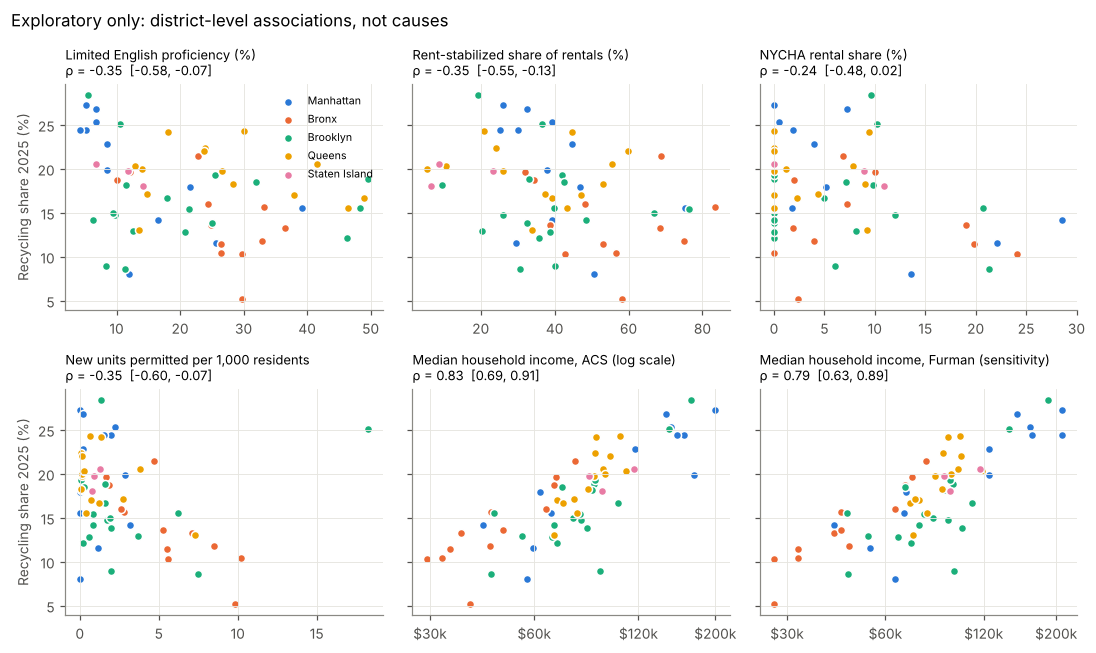

In [11]:
labels = {"lep_pct": "Limited English proficiency (%)", "rent_stab_share": "Rent-stabilized share of rentals (%)",
          "nycha_share": "NYCHA rental share (%)", "permits_per_1k": "New units permitted per 1,000 residents",
          "log_income": "Median household income, ACS (log scale)", "furman": "Median household income, Furman (sensitivity)"}
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharey=True)
for ax, f in zip(axes.flat, FEATURES + ["furman"]):
    # WHY plot income in dollars on a log axis: same shape as log_income, but readers see real dollar amounts.
    xcol = {"log_income": "hh_income", "furman": "furman_income"}.get(f, f)
    for b in BORO_ORDER:
        s = feat[feat.borough == b]
        ax.scatter(s[xcol], s[y], s=28, color=BORO_COLORS[b], edgecolor="white", linewidth=1, label=b)
    if f in ("log_income", "furman"):
        ax.set_xscale("log"); ax.set_xticks([30000, 60000, 120000, 200000], ["$30k", "$60k", "$120k", "$200k"]); ax.minorticks_off()
    r = corr_tbl.set_index("feature").loc["log_income_furman" if f == "furman" else f]
    ax.set_title(f"{labels[f]}\nρ = {r.rho:.2f}  [{r.ci_low:.2f}, {r.ci_high:.2f}]", fontsize=8.5, loc="left")
for ax in axes[:, 0]:
    ax.set_ylabel("Recycling share 2025 (%)")
axes[0, 0].legend(frameon=False, fontsize=7, loc="upper right")
fig.suptitle("Exploratory only: district-level associations, not causes", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fig3_share_vs_features.png", dpi=200); plt.show()

### Do the features overlap each other?
If two features carry the same information, a regression can't separate them and its coefficients become unstable. The **variance inflation factor (VIF)** measures this. A VIF above 5 is a warning, and above 10 is a problem.

In [12]:
def vif_table(X):
    '''VIF for each column: 1 / (1 - R²) from regressing it on the others.

    WHY by hand: it keeps the notebook free of extra installs and shows exactly what VIF means.'''
    Z = (X - X.mean()) / X.std()
    out = {}
    for c in Z:
        others = np.column_stack([np.ones(len(Z)), Z.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(others, Z[c].values, rcond=None)
        resid = Z[c].values - others @ beta
        r2 = 1 - resid.var() / Z[c].values.var()
        out[c] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

print("Spearman correlation among features:\n", feat[FEATURES].corr(method="spearman").round(2).to_string())
print("\nVIF:\n", vif_table(feat[FEATURES]).round(2).to_string())

Spearman correlation among features:
                  lep_pct  rent_stab_share  nycha_share  permits_per_1k  log_income
lep_pct             1.00             0.43        -0.12            0.05       -0.50
rent_stab_share     0.43             1.00        -0.15            0.21       -0.46
nycha_share        -0.12            -0.15         1.00            0.26       -0.31
permits_per_1k      0.05             0.21         0.26            1.00       -0.38
log_income         -0.50            -0.46        -0.31           -0.38        1.00

VIF:
 log_income         2.28
nycha_share        1.63
rent_stab_share    1.56
lep_pct            1.49
permits_per_1k     1.22


## 7. Change over time and the forecasting table
Monthly data gives far more rows than the 59-district snapshot, so forecasting has room to learn. Two things to check first: the long-run trend, and whether the share has a seasonal pattern.

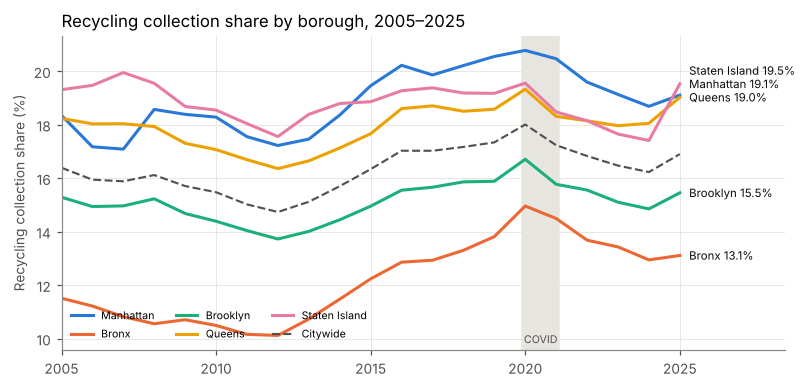

year
2015    16.3
2016    17.0
2017    17.0
2018    17.2
2019    17.3
2020    18.0
2021    17.2
2022    16.8
2023    16.5
2024    16.2
2025    16.9
2026    16.8


In [13]:
m = monthly.copy()
annual_city = m.groupby("year")[["dry_recycling_tons", "core_total_tons"]].sum().pipe(lambda t: t.dry_recycling_tons / t.core_total_tons * 100)
annual_boro = (m.groupby(["year", "borough"])[["dry_recycling_tons", "core_total_tons"]].sum()
               .pipe(lambda t: t.dry_recycling_tons / t.core_total_tons * 100).unstack()[BORO_ORDER])
full_years = annual_boro.loc[:2025]   # WHY: 2026 is a partial year, which would bend the end of the line

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for b in BORO_ORDER:
    ax.plot(full_years.index, full_years[b], color=BORO_COLORS[b], lw=2, label=b)
ax.plot(annual_city.loc[:2025].index, annual_city.loc[:2025], color="#52514e", lw=1.4, ls="--", label="Citywide")
# WHY nudge end labels apart: several boroughs finish within half a point, and stacked labels are unreadable.
ends = full_years.iloc[-1].sort_values()
pos, last = {}, -1e9
for b, v in ends.items():
    last = max(v, last + 0.5); pos[b] = last
for b in BORO_ORDER:
    ax.text(2025.3, pos[b], f"{b} {full_years[b].iloc[-1]:.1f}%", color="#0b0b0b", fontsize=7.5, va="center")
ax.axvspan(2019.9, 2021.1, color="#e6e5e0", zorder=0)
ax.text(2020.5, ax.get_ylim()[0] + 0.15, "COVID", fontsize=7, color="#52514e", ha="center", va="bottom")
ax.set_xlim(first_full, 2028.4); ax.set_ylabel("Recycling collection share (%)")
ax.set_title(f"Recycling collection share by borough, {first_full}–2025", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=7, ncol=3, loc="lower left")
fig.tight_layout(); fig.savefig("figures/fig4_borough_trend.png", dpi=200); plt.show()
print(annual_city.round(1).loc[2015:].to_string())

In [14]:
# WHY deviation from each district-year mean: it isolates the seasonal shape from differences between districts.
m["dev"] = m["recycling_share_pct"] - m.groupby(["boro_cd", "year"])["recycling_share_pct"].transform("mean")
season = m.groupby(m.month.dt.month)["dev"].agg(["mean", "std"])
print("Average gap from the yearly mean, by calendar month (percentage points):")
print(season.round(2).T.to_string())

Average gap from the yearly mean, by calendar month (percentage points):
month    1     2     3     4     5     6     7     8     9     10    11    12
mean   0.86  0.58  0.25 -0.14 -0.66 -0.26 -0.38 -0.49 -0.12 -0.27 -0.69  1.36
std    1.29  1.07  0.85  0.73  0.84  0.69  0.73  0.79  0.67  0.71  1.06  1.07


### Building the monthly modeling table
Each row is one district in one month. Every predictor only looks **backward**:
- `lag1`: share last month
- `lag12`: share in the same month last year

**Date-aware lags.** Matt caught a bug in the first version. Shifting by row position assumes no months are missing, and the irregular pre-2005 records broke that for 137 early-2005 rows, where "12 rows back" was not 12 months back. This version joins on the calendar date instead, so `lag12` is always exactly 12 months earlier. Because the history starts in January 2005, the first usable `lag12` falls in January 2006.
- `roll3`: average of the previous three months (shifted so the current month is never included)
- `month`, `borough`: seasonality and borough level

Rows are split by time, never shuffled: **train** 2005–2023, **validate** 2024, **test** January 2025 onward. Shuffling would let the model peek at the future (Provost & Fawcett, 2013, Ch. 5).

In [15]:
ts = monthly[["month", "boro_cd", "borough", "recycling_share_pct"]].sort_values(["boro_cd", "month"]).copy()

def lag_by_date(df, months):
    '''Share from exactly `months` calendar months earlier, matched on date (not row position).

    WHY a date join: a positional shift silently pairs the wrong months whenever a month is missing.'''
    past = df[["boro_cd", "month", "recycling_share_pct"]].copy()
    past["month"] = past["month"] + pd.DateOffset(months=months)
    return df[["boro_cd", "month"]].merge(past, on=["boro_cd", "month"], how="left")["recycling_share_pct"].values

ts["lag1"] = lag_by_date(ts, 1)
ts["lag2"] = lag_by_date(ts, 2)
ts["lag3"] = lag_by_date(ts, 3)
ts["lag12"] = lag_by_date(ts, 12)
ts["roll3"] = ts[["lag1", "lag2", "lag3"]].mean(axis=1, skipna=False)  # WHY from lags: the current month can never leak in
ts["month_num"] = ts["month"].dt.month
ts = ts.dropna(subset=["lag1", "lag12", "roll3"]).drop(columns=["lag2", "lag3"])

# WHY this check: proves every lag12 really is the same calendar month one year earlier.
chk = ts.sample(200, random_state=1)
src = monthly.set_index(["boro_cd", "month"])["recycling_share_pct"]
assert np.allclose(chk["lag12"], [src[(b, mth - pd.DateOffset(months=12))] for b, mth in zip(chk.boro_cd, chk.month)]), "lag12 misaligned"
print("First month with lag12:", ts["month"].min().date())
ts["split"] = np.select([ts.month < "2024-01-01", ts.month < "2025-01-01"], ["train", "valid"], "test")
print(ts["split"].value_counts().reindex(["train", "valid", "test"]).to_string())
assert (ts.groupby("split")["month"].max()["train"] < ts.groupby("split")["month"].min()["valid"]), "time split overlaps"

First month with lag12: 2006-01-01
split
train    12744
valid      708
test      1298


## 8. Baselines the models must beat
Following Provost & Fawcett (2013, Ch. 5 and Ch. 7), each research question gets a simple, honest baseline:
- **Association (RQ2):** always predict the average share. Measured with leave-one-out, so each district's guess comes from the other 58.
- **Risk (RQ3):** the base rate. Calling every district "not high risk" is right about 75% of the time but finds zero high-risk districts, which is why recall matters more than accuracy. A tougher baseline reuses last year's bottom quarter.
- **Forecast (RQ4):** seasonal naive (repeat the same month last year) and persistence (repeat last month).

In [16]:
yv = feat[y].values
loo_pred = (yv.sum() - yv) / (len(yv) - 1)  # WHY: the mean of the other 58 districts, so no district predicts itself
base_mae, base_rmse = np.abs(yv - loo_pred).mean(), np.sqrt(((yv - loo_pred) ** 2).mean())
print(f"RQ2 mean baseline (LOO): MAE {base_mae:.2f} pp, RMSE {base_rmse:.2f} pp")
print(f"RQ3 base rate: {feat.high_risk.mean():.0%} high risk -> 'never high risk' accuracy {1 - feat.high_risk.mean():.0%}, recall 0%")
# WHY a "last year's list" baseline: shares barely move year to year, so simply reusing 2024's bottom quarter
# may already find most high-risk districts. A model has to beat this, not just the base rate.
prev_flag = (feat["share_2024"] <= feat["share_2024"].quantile(0.25)).astype(int)
tp = int(((prev_flag == 1) & (feat.high_risk == 1)).sum())
print(f"RQ3 last-year list: flags {prev_flag.sum()} districts, catches {tp} of {feat.high_risk.sum()} high-risk "
      f"(recall {tp / feat.high_risk.sum():.0%}, precision {tp / prev_flag.sum():.0%})")

def mae(a, b): return float(np.abs(a - b).mean())
fc = []
for s in ["valid", "test"]:
    t = ts[ts.split == s]
    fc.append({"split": s, "seasonal_naive_MAE": mae(t.recycling_share_pct, t.lag12),
               "persistence_MAE": mae(t.recycling_share_pct, t.lag1), "rows": len(t)})
fc = pd.DataFrame(fc)
print("\nRQ4 forecast baselines (percentage points):\n", fc.round(2).to_string(index=False))

RQ2 mean baseline (LOO): MAE 4.26 pp, RMSE 5.22 pp
RQ3 base rate: 25% high risk -> 'never high risk' accuracy 75%, recall 0%
RQ3 last-year list: flags 15 districts, catches 14 of 15 high-risk (recall 93%, precision 93%)

RQ4 forecast baselines (percentage points):
 split  seasonal_naive_MAE  persistence_MAE  rows
valid                0.70             0.78   708
 test                0.95             1.03  1298


## 9. Save outputs for modeling and for Andrea

In [17]:
keep = ["boro_cd", "borough", y, "high_risk"] + FEATURES + ["log_income_furman", "share_2024", "share_2019", "hh_income", "furman_income", "income_flagged"]
feat[keep].to_csv("features/district_features_2025.csv", index=False)
ts.to_csv("features/monthly_model_table.csv", index=False)
corr_tbl.to_csv("features/feature_correlations.csv", index=False)
pd.DataFrame({"model": ["RQ2 mean (LOO)", "RQ4 seasonal naive (test)", "RQ4 persistence (test)"],
              "MAE_pp": [base_mae, fc.set_index("split").loc["test", "seasonal_naive_MAE"], fc.set_index("split").loc["test", "persistence_MAE"]]}
             ).to_csv("features/baselines.csv", index=False)
print(sorted(os.listdir("features")), sorted(os.listdir("figures")))

['baselines.csv', 'district_features_2025.csv', 'feature_correlations.csv', 'monthly_model_table.csv'] ['fig1_district_ranking_2025.png', 'fig2_borough_share_2025.png', 'fig3_share_vs_features.png', 'fig4_borough_trend.png']


## 10. Findings
1. **The gaps are between districts, not just boroughs.** Shares ran from 5.1% (Bronx 2) to 28.4% (Brooklyn 6) against a citywide 16.9%. Within Brooklyn the spread is 19.8 points and within Manhattan 19.2 points, wider than the 6.4-point gap between the best and worst boroughs. Outreach planned at the district level will reach the problem better than a borough-wide campaign. That is the "zoom in" lesson from *Everybody Lies* (Ch. 5).
2. **Income lines up most strongly with recycling share** (ACS ρ = 0.83, 95% CI 0.69 to 0.91). The link holds with Furman income (ρ = 0.79) and without Manhattan 1's top-coded value (ρ = 0.82), so it doesn't depend on the source or one district. Limited English proficiency, rent-stabilized housing and new permits each show a moderate negative link (ρ ≈ −0.35, intervals clear of zero). NYCHA share is uncertain, since its interval crosses zero.
3. **Some of those links may be income in disguise.** Language access (ρ = −0.50) and rent-stabilized share (ρ = −0.46) both move with income. The regression has to hold income constant before the team says language or housing matters on its own. All VIFs are below 2.3, so the features can sit in one model.
4. **The ranking barely changes year to year.** The 2024 share predicts the 2025 share almost perfectly (ρ = 0.99). Simply reusing last year's bottom quarter catches 14 of the 15 high-risk districts. A community-feature classifier is unlikely to beat that list for **flagging** districts. Its value is in **explaining** why districts are low and spotting ones drifting downward. Worth raising at the team check-in.
5. **The citywide trend has turned twice.** The share climbed from 14.7% in 2012 to 18.0% in 2020, slid to 16.2% by 2024, and rose to 16.9% in 2025. The Bronx stays lowest throughout but gained the most from 2012 to 2020.
6. **Recycling has a holiday season.** December runs about 1.4 points above a district's yearly average and January about 0.9 points above, while May and November run about 0.7 below. Forecast models need calendar month as a feature.
7. **The bars to beat:** guessing the average misses a district's 2025 share by 4.26 points on average, and the seasonal naive forecast misses a month by 0.95 points on the test period.

**Data cautions:** ACS income comes from CDTAs that approximate districts (46 of 59), Manhattan 1's income looks top-coded with no margin of error, and the features come from different years (language 2015–2019, income 2020–2024, housing 2025).

**Next (modeling notebook):** regression and ridge for RQ2 against the 4.26-point baseline; the RQ3 classifier against last year's list; gradient boosting for RQ4 against seasonal naive.

## References
Provost, F., & Fawcett, T. (2013). *Data science for business: What you need to know about data mining and data-analytic thinking*. O'Reilly Media.

Stephens-Davidowitz, S. (2017). *Everybody lies: Big data, new data, and what the internet can tell us about who we really are*. Dey Street Books.

New York City Department of City Planning. (2025). *Economic profiles, 2020–2024 ACS 5-year estimates by Community District Tabulation Area* [Data set]. https://www.nyc.gov/content/planning/pages/resources/datasets/american-community-survey

New York City Department of Sanitation. (2026). *DSNY monthly tonnage data* [Data set]. NYC Open Data. https://data.cityofnewyork.us/d/ebb7-mvp5

NYU Furman Center. (2025). *CoreData.nyc neighborhood indicators* [Data set]. https://www.furmancenter.org/data-tools-resources/data-tools-data-downloads/